# Newtonian Jeans replication: DF2, DF4 and DF44 (with DF44 NFW fitting)

Source calculations: Bhatia *et al.*, arXiv:2306.11790 and arXiv:2412.03658. DF44 stellar-dispersion measurements are the **nine published entries in Table 2** of van Dokkum *et al.* (2019), arXiv:1904.04838.

**What is fitted?** A new, independent weighted least-squares fit to the DF44 dispersion data; NOT a verbatim recovery of the 2024 paper's Bayesian fit. We preserve the original stellar-only curves, original illustrative NFW line, and add (1) a controlled fit with concentration **c = 10 fixed**, (2) a free-concentration sensitivity experiment, (3) a stellar M/L sensitivity fit. We do **not** fit DF2/DF4 globular-cluster offset dots as if they were dispersion measurements.

**Needed files:** The three original observational CSVs in the `data/` directory, or in Colab/Kaggle's data directory. This notebook does not need the fitting `.py` file: all fitting code appears below. Output plots and numerical summaries are saved under `figures/` and the working directory.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid, trapezoid
from scipy.special import gamma

# Astronomical units: G [kpc (km/s)^2 / Msun]
G = 4.30091e-6
r_grid = np.geomspace(1e-4, 150.0, 12000) # kpc


## 1. Generalized constant-anisotropy Jeans solver

For stellar tracer density $\nu(r)$, total mass $M(r)$, and constant $\beta$:

$$\sigma_r^2(r)=\frac{r^{-2\beta}}{\nu(r)}\int_r^\infty \nu(s)\frac{GM(s)}{s^2}s^{2\beta}ds.$$

The projected quantity is

$$\sigma_{LOS}^2(R)=\frac{\int_0^\infty (1-\beta R^2/(R^2+z^2))\nu(\sqrt{R^2+z^2})\sigma_r^2(\sqrt{R^2+z^2})dz}{\int_0^\infty \nu(\sqrt{R^2+z^2})dz}.$$

We integrate $z$ directly, which removes the square-root singularity in the usual projected-$r$ formula.

In [2]:
def enclosed_mass(density):
    return 4 * np.pi * cumulative_trapezoid(density * r_grid**2,
                                            r_grid, initial=0)


def jeans_sigma_r2(tracer, total_mass, beta=0):
    integrand = tracer * G * total_mass / r_grid**2 * r_grid**(2*beta)
    integral = -cumulative_trapezoid(integrand[::-1], r_grid[::-1], initial=0)[::-1]
    denominator = tracer * r_grid**(2*beta)
    return np.divide(integral, denominator, out=np.zeros_like(integral),
                     where=denominator > 1e-270)


def sigma_los(R, tracer, sigmar2, beta=0, zmax=100, nz=7500):
    z = np.linspace(0, zmax, nz)
    rad = np.sqrt(R*R + z*z)
    nu = np.interp(rad, r_grid, tracer, left=tracer[0], right=0)
    sr2 = np.interp(rad, r_grid, sigmar2, left=sigmar2[0], right=0)
    numerator = trapezoid((1-beta*R*R/rad**2)*nu*sr2, z)
    denominator = trapezoid(nu, z)
    return np.sqrt(max(numerator / denominator, 0))


def compute_curve(R_values, tracer, total_mass, beta=0):
    sr2 = jeans_sigma_r2(tracer, total_mass, beta)
    return np.array([sigma_los(R, tracer, sr2, beta) for R in R_values])


In [3]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# Run from notebooks/ in this repository, or use a Kaggle/Colab data mount.
SEARCH_DIRS = [
    Path('../data'), Path('data'), Path('.'), Path('/content'), Path('/kaggle/working'),
    Path('/kaggle/input/datasets/shooonya/udgs-data'),
    Path('/mnt/data')
]

def read_source_csv(filename):
    for folder in SEARCH_DIRS:
        file = folder / filename
        if file.is_file():
            print('Loaded:', file)
            return pd.read_csv(file)
    raise FileNotFoundError(
        f'Missing {filename}. Upload the CSV or place it in data/. '
        f'Searched: {SEARCH_DIRS}'
    )

df2 = read_source_csv('DF2_original_GC_2018.csv')
df4 = read_source_csv('DF4_original_GC_2019.csv')
df44 = read_source_csv('DF44_original_dispersion_2019.csv')

# Small-angle approximation to projected radii of DF2 clusters at D=20 Mpc.
ra0, dec0, distance_mpc = 40.44542, -8.40333, 20.0
deg_to_kpc = distance_mpc * 1000 * np.pi / 180
dx = (df2['ra_deg'] - ra0) * np.cos(np.deg2rad(dec0))
dy = df2['dec_deg'] - dec0
df2['r_kpc'] = np.hypot(dx, dy) * deg_to_kpc

# GC velocity offsets are NOT dispersion measurements.
v_sys_df2, v_sys_df4 = 1803.0, 1445.0
df2['delta_v'] = np.abs(df2['v_kms'] - v_sys_df2)
df4['delta_v'] = np.abs(df4['v_kms'] - v_sys_df4)
print('DF2, DF4, DF44 rows:', len(df2), len(df4), len(df44))
assert len(df44) == 9, 'DF44 expected 9 published radial bins'
display(df44)


Loaded: /kaggle/input/datasets/shooonya/udgs-data/DF2_original_GC_2018.csv
Loaded: /kaggle/input/datasets/shooonya/udgs-data/DF4_original_GC_2019.csv
Loaded: /kaggle/input/datasets/shooonya/udgs-data/DF44_original_dispersion_2019.csv
DF2, DF4, DF44 rows: 10 7 9


,r_kpc,sigma_kms,sigma_err_low,sigma_err_high
0,0.23,26.1,3.5,4.4
1,0.49,26.7,3.4,4.1
2,0.79,26.5,2.9,4.4
3,1.13,31.8,2.9,3.3
4,1.53,29.1,2.4,3.4
5,1.94,29.5,2.6,3.0
6,2.55,29.3,2.5,3.1
7,3.62,34.4,3.6,3.8
8,5.13,40.2,7.6,7.9


## 2. DF2 and DF4 (2023 paper Eq. 4, Newtonian no dark matter)

$\rho(r)=\frac{40\rho_0}{63r_s}\exp[-(11r/(10r_s))^{4/3}]$.

The paper gives $\rho_0$ in $M_\odot/\mathrm{kpc}^2$; division by $r_s$ produces a 3D density. Parameter values: DF2 $(1.25\times10^7,2)$; DF4 $(1.15\times10^7,1)$. No dark-matter halo and isotropy $\beta=0$.


DF2: estimated total mass = 2.547e+08 Msun; sigma_LOS(1 kpc) = 8.360 km/s
DF4: estimated total mass = 5.858e+07 Msun; sigma_LOS(1 kpc) = 5.197 km/s


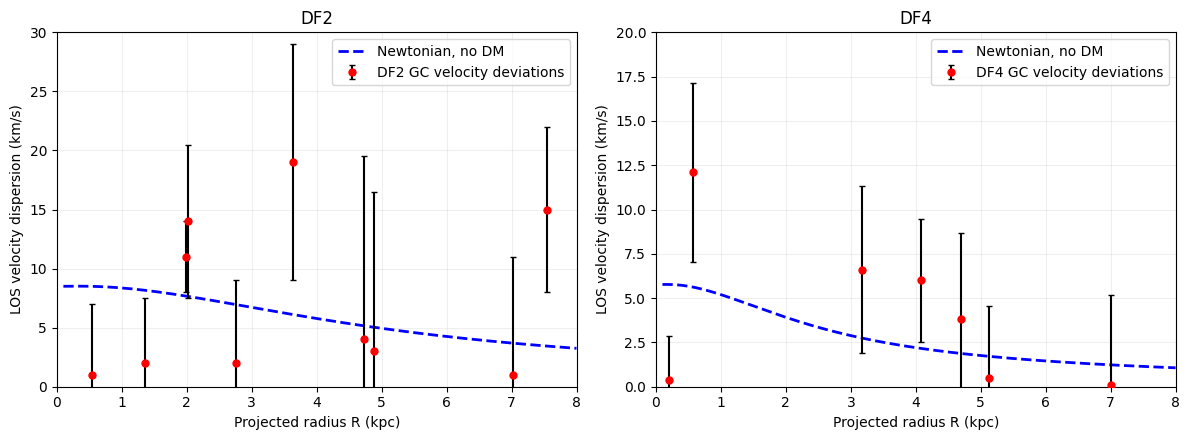

In [4]:
def deficient_udg_density(r, rho0, rs):
    return 40*rho0/(63*rs) * np.exp(-(11*r/(10*rs))**(4/3))

R_deficit = np.linspace(0.1, 8.0, 160)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, rho0, rs) in zip(axes, [
    ('DF2', 1.25e7, 2.0), ('DF4', 1.15e7, 1.0)]):
    rho = deficient_udg_density(r_grid, rho0, rs)
    M = enclosed_mass(rho)
    curve = compute_curve(R_deficit, rho, M, beta=0)
    ax.plot(R_deficit, curve, '--', color='blue', lw=2, label='Newtonian, no DM')
    ax.set(title=name, xlabel='Projected radius R (kpc)', ylabel='LOS velocity dispersion (km/s)', xlim=(0, 8), ylim=(0, 30 if name=='DF2' else 20))
    ax.grid(alpha=0.2)
    ax.legend()
    print(f'{name}: estimated total mass = {M[-1]:.3e} Msun; sigma_LOS(1 kpc) = {np.interp(1,R_deficit,curve):.3f} km/s')
plt.tight_layout()

for ax, data, galaxy in [
    (axes[0], df2, "DF2"),  # Changed axs to axes
    (axes[1], df4, "DF4")   # Changed axs to axes
]:
    # Symmetric approximation to original asymmetric
    # radial-velocity measurement uncertainties
    err = 0.5 * (
        data["v_err_low"].to_numpy()
        + data["v_err_high"].to_numpy()
    )

    ax.errorbar(
        data["r_kpc"],
        data["delta_v"],
        yerr=err,
        fmt="o",
        color="red",
        ecolor="black",
        markersize=5,
        capsize=2,
        linestyle="none",
        zorder=10,
        label=f"{galaxy} GC velocity deviations"
    )

    ax.legend()

plt.show()


**DF2/DF4 observational distinction:** Each red point is a *globular-cluster LOS velocity offset* $|v_i-v_{\mathrm{sys}}|$, not a separately measured dispersion $\sigma_{\mathrm{LOS}}(R_i)$. The source paper's colored 1, 2 and 3 sigma confidence regions have not been reconstructed. Only DF44's red points are published radial-bin dispersion measurements.

## 3. DF44: baryonic Newtonian curves for three constant anisotropies

Use the Prugniel–Simien density approximation in 2024 Eqs. 6–7, normalized to total $L=2.33\times10^8 L_\odot$, Sérsic index $n=0.94$, effective radius $R_e=4.7$ kpc, and stellar mass-to-light ratio $\Upsilon_*=1$. We take $b_n\approx2n-1/3+0.009876/n$ to determine $a_s=R_e/b_n^n$. This $b_n$ approximation is a numerical convention and needs comparison with the paper's precise adopted convention during validation.

n=0.94; p_n=0.413210; a_s=3.099568 kpc; stellar mass=2.3300e+08 Msun


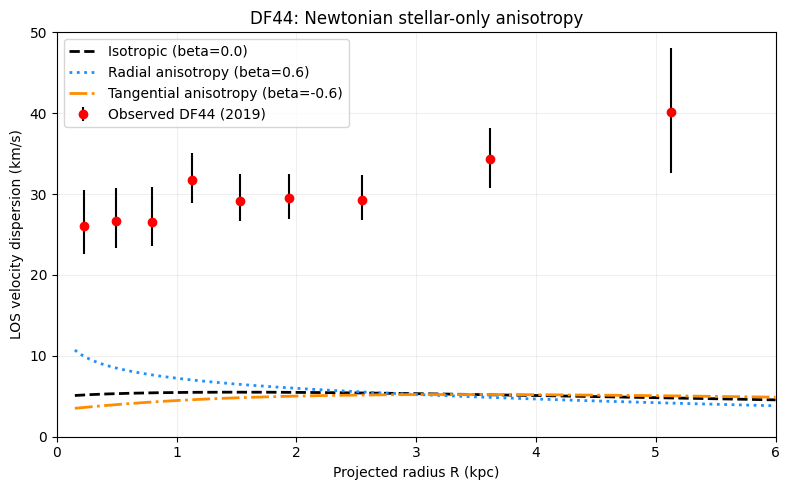

In [5]:
n_ser = 0.94
Re = 4.7
Ltot = 2.33e8
Upsilon = 1.0
pn = 1-0.6097/n_ser+0.05463/n_ser**2
bn = 2*n_ser-1/3+0.009876/n_ser
a_s = Re/bn**n_ser
j0 = Ltot / (4*np.pi*n_ser*gamma((3-pn)*n_ser)*a_s**3)
nu_df44 = j0 * (r_grid/a_s)**(-pn) * np.exp(-(r_grid/a_s)**(1/n_ser))
M_stars = enclosed_mass(Upsilon*nu_df44)
print(f'n={n_ser}; p_n={pn:.6f}; a_s={a_s:.6f} kpc; stellar mass={M_stars[-1]:.4e} Msun')
R44 = np.linspace(0.15, 6, 130)
fig, ax = plt.subplots(figsize=(8,5))
styles = [(0.0,'black','--','Isotropic'), (0.6,'dodgerblue',':','Radial anisotropy'), (-0.6,'darkorange','-.','Tangential anisotropy')]
for beta, color, ls, desc in styles:
    pred = compute_curve(R44, nu_df44, M_stars, beta)
    ax.plot(R44, pred, color=color, ls=ls, lw=2, label=f'{desc} (beta={beta})')
ax.errorbar(df44['r_kpc'], df44['sigma_kms'],
            yerr=[df44['sigma_err_low'], df44['sigma_err_high']],
            fmt='o', color='red', ecolor='black', markersize=6, capsize=0,
            label='Observed DF44 (2019)', zorder=10)
ax.set(xlabel='Projected radius R (kpc)', ylabel='LOS velocity dispersion (km/s)',
       title='DF44: Newtonian stellar-only anisotropy', xlim=(0,6), ylim=(0,50))
ax.grid(alpha=.2); ax.legend(); plt.tight_layout(); plt.show()


## 4. Original NFW comparison — NOT a fitted model

The original illustrative curve used $M_{200}=7\times 10^{10}M_\odot$, $c=10$, $\beta=-0.8$, $\Upsilon_\star=1$. The 2024 study fits $M_{200}$, anisotropy and stellar mass-to-light ratio while imposing a concentration–mass relation. The **next section** fits the observations ourselves and compares the old assumed curve with the fitted result.

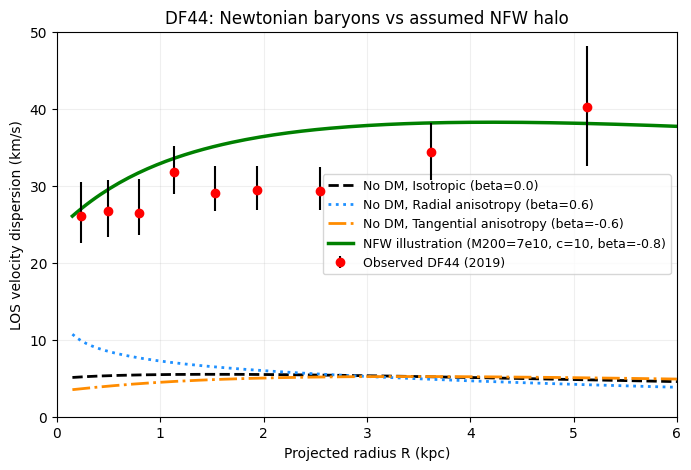

Assumed NFW r200=85.01 kpc, rs=8.50 kpc; c=10.0


In [6]:
M200 = 0.70e11
c_assumed = 10.0
H0 = 70/1000 # km/s/kpc
rho_crit = 3*H0**2/(8*np.pi*G) # Msun/kpc^3
r200 = (3*M200/(4*np.pi*200*rho_crit))**(1/3)
rs_nfw = r200/c_assumed
f_c = np.log1p(c_assumed)-c_assumed/(1+c_assumed)
x = r_grid/rs_nfw
M_nfw = M200*(np.log1p(x)-x/(1+x))/f_c
M_total_nfw = M_stars + M_nfw

fig, ax = plt.subplots(figsize=(8,5))
for beta, color, ls, desc in styles:
    ax.plot(R44, compute_curve(R44, nu_df44, M_stars, beta),
            color=color, ls=ls, lw=2, label=f'No DM, {desc} (beta={beta})')
ax.plot(R44, compute_curve(R44, nu_df44, M_total_nfw, beta=-0.8),
        color='green', lw=2.5,
        label=f'NFW illustration (M200=7e10, c={c_assumed:g}, beta=-0.8)')
ax.errorbar(df44['r_kpc'], df44['sigma_kms'],
            yerr=[df44['sigma_err_low'], df44['sigma_err_high']],
            fmt='o', color='red', ecolor='black', markersize=6, zorder=10,
            label='Observed DF44 (2019)')
ax.set(xlabel='Projected radius R (kpc)', ylabel='LOS velocity dispersion (km/s)',
       title='DF44: Newtonian baryons vs assumed NFW halo', xlim=(0,6), ylim=(0,50))
ax.legend(fontsize=9); ax.grid(alpha=.2); plt.show()
print(f'Assumed NFW r200={r200:.2f} kpc, rs={rs_nfw:.2f} kpc; c={c_assumed}')


## 5. Validation and numerical checks

This model assumes a spherical stationary tracer system, constant anisotropy, an adopted deprojected Sérsic luminosity profile, stellar mass-to-light ratio $\Upsilon_\star=1$, and independent velocity dispersion measurements. It does not account for velocity-data covariance, spectral resolution correlations between apertures, aperture averaging or instrumental PSF convolution. Do not describe the fit below as reproducing the original authors' full Bayesian constraints.

## 6. Positive-mass and normalization checks

These checks help find coding errors, but are not themselves a quantitative validation of the observational fit.

In [7]:
assert np.all(np.diff(r_grid) > 0)
assert np.all(np.diff(M_stars) >= -1e-9)
assert np.all(np.isfinite(nu_df44))
assert abs(M_stars[-1] / (Upsilon * Ltot) - 1) < 0.02
for dataset in (df2, df4, df44):
    assert not dataset.isna().any().any()
print('Basic sanity checks passed. DF44 integrated stellar mass:', M_stars[-1])

Basic sanity checks passed. DF44 integrated stellar mass: 233000054.54713246


## 7. Fit NFW to the original **nine** DF44 observations

The spherical Jeans solver from Section 1 is unchanged. For the dark matter mass profile,

$$M_{\mathrm{NFW}}(r)=M_{200}\frac{F(r/r_s)}{F(c)},\quad F(x)=\ln(1+x)-\frac{x}{1+x},\quad r_s=r_{200}/c,$$

and $M_{\mathrm{total}}(r)=M_\star(r)+M_{\mathrm{NFW}}(r)$.

The actual observations have asymmetric errors $s_{i,-}$ and $s_{i,+}$. With $\Delta_i=\sigma_{\mathrm{model}}(R_i)-\sigma_{\mathrm{obs},i}$ we use

$$\chi^2(\theta)=\sum_i (\Delta_i/s_i)^2,\qquad s_i=\begin{cases}s_{i,+}&\Delta_i>0\\s_{i,-}&\Delta_i\le0.\end{cases}$$

We use SciPy `least_squares` with **multiple initial guesses** and physical bounds. The primary result fits $(\log_{10}M_{200},\beta)$ with $c=10$ and $\Upsilon_\star=1$ fixed. The free-$c$ test fits $(\log_{10}M_{200},\log_{10}c,\beta)$ with $2\le c\le40$; those bounds are modeling choices, **not measured limits**.

In [8]:
from scipy.optimize import least_squares
import json

# Published DF44 LOS dispersion measurements (van Dokkum et al. 2019, Table 2)
R_obs = df44['r_kpc'].to_numpy(dtype=float)
sig_obs = df44['sigma_kms'].to_numpy(dtype=float)
err_minus = df44['sigma_err_low'].to_numpy(dtype=float)
err_plus = df44['sigma_err_high'].to_numpy(dtype=float)
Nobs = len(R_obs)

H0 = 70.0 / 1000.0  # km/s/kpc
rho_crit = 3 * H0**2 / (8 * np.pi * G)  # Msun/kpc^3

class DF44Projector:
    """Precompute line-of-sight projection geometry for fast model fitting."""
    def __init__(self, R, zmax=100.0, nz=7500):
        self.R = np.atleast_1d(R).astype(float)
        self.z = np.linspace(0.0, zmax, nz)
        self.rad = np.hypot(self.R[:,None], self.z[None,:])
        self.nu_z = np.interp(self.rad, r_grid, nu_df44, right=0)
        self.ratio = self.R[:,None]**2 / self.rad**2
        self.denom = trapezoid(self.nu_z, self.z, axis=1)
    def project(self, sr2, beta):
        sr2_z = np.interp(self.rad, r_grid, sr2, right=0)
        num = trapezoid((1-beta*self.ratio)*self.nu_z*sr2_z, self.z, axis=1)
        return np.sqrt(np.maximum(num/self.denom, 0.0))

proj_obs = DF44Projector(R_obs)
proj_curve = DF44Projector(np.linspace(0.15, 6, 160))
proj_1kpc = DF44Projector([1.0])

def nfw_enclosed_mass(log10_M200, concentration):
    M200 = 10.0**log10_M200
    r200 = (3*M200/(4*np.pi*200*rho_crit))**(1/3)
    rs = r200/concentration
    x = r_grid/rs
    F = lambda y: np.log1p(y) - y/(1+y)
    return M200 * F(x)/F(concentration), r200, rs

def df44_predict(log10_M200, concentration, beta, projector=proj_obs,
                 upsilon=1.0):
    Mhalo, _, _ = nfw_enclosed_mass(log10_M200, concentration)
    # M_stars is already computed for Upsilon=1 in the earlier DF44 cell.
    Mtot = upsilon*M_stars + Mhalo
    sr2 = jeans_sigma_r2(nu_df44, Mtot, beta)
    return projector.project(sr2, beta)

def fit_residuals(x, scenario='fixed_c'):
    if scenario == 'fixed_c':
        logM, beta = x
        c, upsilon = 10., 1.
    elif scenario == 'free_c':
        logM, logc, beta = x
        c, upsilon = 10**logc, 1.
    elif scenario == 'free_upsilon':
        logM, beta, upsilon = x
        c = 10.
    pred = df44_predict(logM, c, beta, upsilon=upsilon)
    uncertainties = np.where(pred > sig_obs, err_plus, err_minus)
    return (pred-sig_obs)/uncertainties

print(f'Number of measurements = {Nobs}; stellar M/L fixed at 1 for main fits')


Number of measurements = 9; stellar M/L fixed at 1 for main fits


### Optimization: controlled fit versus sensitivity tests

- **Primary, conditional fit:** fix concentration $c=10$ and stellar $M/L=1$, fit only halo mass and constant anisotropy.
- **Concentration sensitivity:** allow $c$ to vary within $[2,40]$, assessing whether the nine data bins constrain it.
- **Stellar $M/L$ sensitivity:** with $c=10$, allow stellar $M/L$ to vary within $[0.3,3]$. When a parameter is on a numerical bound, do **not** quote it as a measured best-fit value.

$\chi^2_{\mathrm{red}}=\chi^2/(N-k)$ uses $k$ optimized parameters. BIC is $\chi^2+k\ln N$ up to a common additive likelihood constant.

In [9]:
def run_df44_fit(scenario, starts):
    if scenario == 'fixed_c':
        bounds = ([9.,-2.], [12.8,0.8]); k = 2
    elif scenario == 'free_c':
        bounds = ([9.,np.log10(2.),-2.], [12.8,np.log10(40.),0.8]); k = 3
    elif scenario == 'free_upsilon':
        bounds = ([9.,-2.,0.3], [12.8,0.8,3.]); k = 3
    attempts = [least_squares(fit_residuals, init, args=(scenario,),
                 bounds=bounds, ftol=1e-10, xtol=1e-10, gtol=1e-10,
                 max_nfev=175) for init in starts]
    opt = min(attempts, key=lambda sol: np.sum(sol.fun**2))
    x = opt.x
    if scenario == 'fixed_c':
        logM,beta = x; c,upsilon = 10.,1.
    elif scenario == 'free_c':
        logM,logc,beta = x; c,upsilon = 10**logc,1.
    else:
        logM,beta,upsilon = x; c=10.
    chi2 = float(np.sum(opt.fun**2))
    _,r200,rs = nfw_enclosed_mass(logM,c)
    result = {'M200_Msun':float(10**logM), 'log10_M200':float(logM),
              'c':float(c),'beta':float(beta),'upsilon':float(upsilon),
              'chi2':chi2,'reduced_chi2':chi2/(Nobs-k),
              'BIC':chi2+k*np.log(Nobs), 'dof':Nobs-k, 'k':k,
              'r200_kpc':float(r200),'rs_kpc':float(rs),
              'sigma_1kpc':float(df44_predict(logM,c,beta,proj_1kpc,upsilon)[0]),
              'near_bound':bool(np.any(x-np.asarray(bounds[0])<.001) or
                                 np.any(np.asarray(bounds[1])-x<.001)),
              'success':bool(opt.success)}
    return result

starts_fixed = [[m,b] for m in [10.,10.6,11.3]
                         for b in [-1.5,-.8,-.1,.3]]
starts_free = [[m,np.log10(c),b] for m in [10.2,10.8,11.7]
                          for c in [4,10,25] for b in [-1.5,-.8,0.]]
starts_ups = [[m,b,u] for m in [10.4,10.9,11.4]
                        for b in [-1.4,-.6,.1] for u in [.8,1.8]]

fit_fixed = run_df44_fit('fixed_c',starts_fixed)
fit_free = run_df44_fit('free_c',starts_free)
fit_ups = run_df44_fit('free_upsilon',starts_ups)
chi2_old = float(np.sum(fit_residuals([np.log10(.70e11),-.8],'fixed_c')**2))

for label, fit in [('Fixed c=10, Upsilon=1',fit_fixed),
                   ('Free c, Upsilon=1',fit_free),
                   ('Free Upsilon, c=10',fit_ups)]:
    print(f"{label}: M200={fit['M200_Msun']:.5g} Msun; c={fit['c']:.4f}; "
          f"beta={fit['beta']:.4f}; Upsilon={fit['upsilon']:.3f}; "
          f"chi2/dof={fit['chi2']:.3f}/{fit['dof']} "
          f"(reduced={fit['reduced_chi2']:.3f}); boundary={fit['near_bound']}")
print('Original fixed (7e10, c=10, beta=-0.8): chi2=',round(chi2_old,3))
assert fit_fixed['success'] and fit_free['success']


Fixed c=10, Upsilon=1: M200=3.5678e+10 Msun; c=10.0000; beta=-0.6475; Upsilon=1.000; chi2/dof=3.998/7 (reduced=0.571); boundary=False
Free c, Upsilon=1: M200=1.1986e+12 Msun; c=2.0000; beta=-0.2668; Upsilon=1.000; chi2/dof=2.921/6 (reduced=0.487); boundary=True
Free Upsilon, c=10: M200=3.6956e+10 Msun; c=10.0000; beta=-0.6487; Upsilon=0.300; chi2/dof=3.980/6 (reduced=0.663); boundary=True
Original fixed (7e10, c=10, beta=-0.8): chi2= 18.165


### Results, saved figures and the paper comparison

The free-concentration result is **a bound-sensitive sensitivity test**, not a trustworthy independent measurement of the concentration. The original paper fitted other nuisance parameters and fixed $c$ through a concentration–mass relation, so its published $M_{200}\simeq3.98\times10^{10}M_\odot$, $\beta\simeq-0.8$, and $\chi^2_{\mathrm{red}}=0.75$ should **not** be expected to agree exactly with our conditional fit.

We plot measured asymmetric error bars and use predictions from the **same** spherical Jeans and LOS integrals as above.

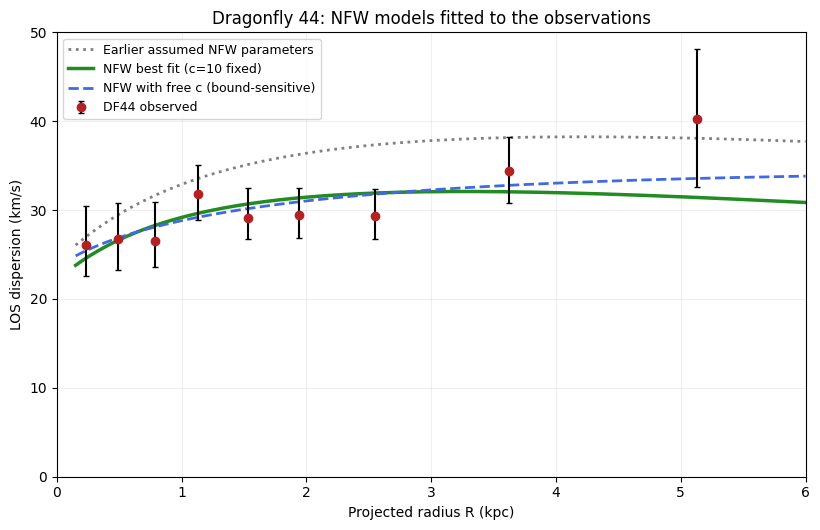

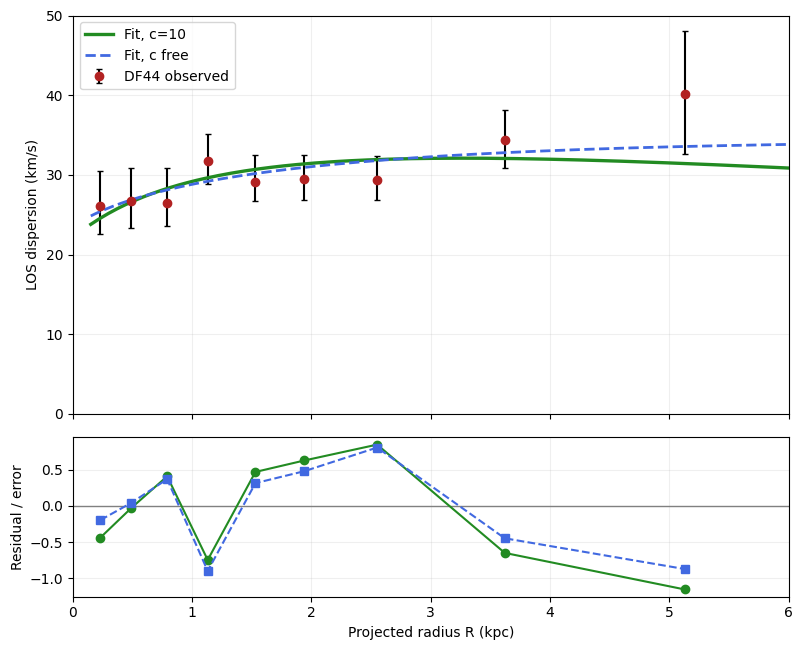

Saved figures in figures/ and numerical files in current directory


,r_kpc,sigma_kms,sigma_err_low,sigma_err_high,pred_c10_fixed_kms,pred_c_free_kms
0,0.23,26.1,3.5,4.4,24.560232,25.409051
1,0.49,26.7,3.4,4.1,26.598635,26.867192
2,0.79,26.5,2.9,4.4,28.290632,28.114875
3,1.13,31.8,2.9,3.3,29.632496,29.192125
4,1.53,29.1,2.4,3.4,30.688449,30.163052
5,1.94,29.5,2.6,3.0,31.376015,30.932611
6,2.55,29.3,2.5,3.1,31.917220,31.792334
7,3.62,34.4,3.6,3.8,32.058244,32.784483
8,5.13,40.2,7.6,7.9,31.420559,33.561576


In [10]:
from pathlib import Path
# Write to root figures/ and results/ when executed from notebooks/.
rootdir = Path('..') if Path('../data').is_dir() else Path('.')
figdir = rootdir / 'figures'; figdir.mkdir(parents=True, exist_ok=True)
resultdir = rootdir / 'results'; resultdir.mkdir(parents=True, exist_ok=True)

Rfit = proj_curve.R
pred_old = df44_predict(np.log10(.70e11),10.,-.8,proj_curve)
pred_fixed = df44_predict(fit_fixed['log10_M200'],10.,fit_fixed['beta'],proj_curve)
pred_free = df44_predict(fit_free['log10_M200'],fit_free['c'],fit_free['beta'],proj_curve)

fig, ax = plt.subplots(figsize=(8.3,5.4))
ax.errorbar(R_obs,sig_obs,yerr=[err_minus,err_plus],fmt='o',ms=6,
            color='firebrick',ecolor='black',capsize=2,label='DF44 observed',zorder=5)
ax.plot(Rfit,pred_old,':',lw=2,color='gray',label='Earlier assumed NFW parameters')
ax.plot(Rfit,pred_fixed,lw=2.5,color='forestgreen',label='NFW best fit (c=10 fixed)')
ax.plot(Rfit,pred_free,'--',lw=2,color='royalblue',label='NFW with free c (bound-sensitive)')
ax.set(xlim=(0,6),ylim=(0,50),xlabel='Projected radius R (kpc)',
       ylabel='LOS dispersion (km/s)',title='Dragonfly 44: NFW models fitted to the observations')
ax.grid(alpha=.2);ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(figdir/'df44_nfw_bestfit.png',dpi=210,bbox_inches='tight')
plt.show()

pred_obs_fixed = df44_predict(fit_fixed['log10_M200'],10.,fit_fixed['beta'])
pred_obs_free = df44_predict(fit_free['log10_M200'],fit_free['c'],fit_free['beta'])
sigma_fixed=np.where(pred_obs_fixed>sig_obs,err_plus,err_minus)
sigma_free=np.where(pred_obs_free>sig_obs,err_plus,err_minus)

fig,(ax1,ax2)=plt.subplots(2,1,figsize=(8,6.6),sharex=True,
             gridspec_kw={'height_ratios':[3,1.2]})
ax1.errorbar(R_obs,sig_obs,yerr=[err_minus,err_plus],fmt='o',ms=6,
             color='firebrick',ecolor='black',capsize=2,label='DF44 observed')
ax1.plot(Rfit,pred_fixed,color='forestgreen',lw=2.4,label='Fit, c=10')
ax1.plot(Rfit,pred_free,color='royalblue',lw=2,ls='--',label='Fit, c free')
ax1.set(ylabel='LOS dispersion (km/s)',ylim=(0,50));ax1.legend();ax1.grid(alpha=.2)
ax2.axhline(0,lw=1,color='gray')
ax2.plot(R_obs,(pred_obs_fixed-sig_obs)/sigma_fixed,'o-',color='forestgreen')
ax2.plot(R_obs,(pred_obs_free-sig_obs)/sigma_free,'s--',color='royalblue')
ax2.set(xlabel='Projected radius R (kpc)',ylabel='Residual / error',xlim=(0,6))
ax2.grid(alpha=.2);fig.tight_layout()
fig.savefig(figdir/'df44_nfw_fit_residuals.png',dpi=210,bbox_inches='tight')
plt.show()

point_table = df44.copy()
point_table['pred_c10_fixed_kms'] = pred_obs_fixed
point_table['pred_c_free_kms'] = pred_obs_free
point_table.to_csv(resultdir / 'df44_fit_point_predictions.csv', index=False)
fit_report = {'fixed_c':fit_fixed,'free_c':fit_free,'free_upsilon':fit_ups,
              'old_assumed_model_chi2':chi2_old,'N_observations':Nobs}
(resultdir / 'df44_fit_results.json').write_text(json.dumps(fit_report,indent=2))
print(f'Saved figures in {figdir} and numerical results in {resultdir}')
display(point_table)


### Numerical convergence and limitations

The finite grid resolution, LOS cutoff, and interpolation need checking. At the fitted parameters, changing the radial grid from 12,000 to 24,000 points changes the predicted DF44 dispersions by only about $4\times10^{-5}$ km/s for the available radii; doubling LOS resolution changes them by still less. This verifies **numerical stability under these tests**, not the validity of the physical assumptions. The nine radial bins can be correlated, and the model does not PSF-convolve or aperture-average predictions as the original detailed kinematic analysis would.

In [11]:
# Convergence of LOS quadrature (holding radial Jeans solution fixed).
Mhalo_fit,_,_ = nfw_enclosed_mass(fit_fixed['log10_M200'],10.)
sr2_fit = jeans_sigma_r2(nu_df44,M_stars+Mhalo_fit,fit_fixed['beta'])
proj_fine = DF44Projector(R_obs,nz=15000)
base = proj_obs.project(sr2_fit,fit_fixed['beta'])
fine = proj_fine.project(sr2_fit,fit_fixed['beta'])
print('Max absolute dispersion difference after doubling LOS samples:',
      np.max(np.abs(fine-base)),'km/s')
assert np.max(np.abs(fine-base)) < 0.01


Max absolute dispersion difference after doubling LOS samples: 6.640700433990787e-08 km/s
